### *Mauricio Rios Cantillo - Jose Bonett Pertuz - Jorge Jaraba Potes - Jordan Caro Batista*

##### **CLASIFICACION DE VOCALES QUE ESTAN EN IMAGENES POR MEDIO DE MACHINE LEARNING**
---

# Descripción del problema

En el presente trabajo se busca construir un modelo de aprendizaje automático capaz de identificar qué vocal (A, E, I, O o U) aparece en una imagen. Se trata de un problema de **clasificación supervisada multiclase**: cada imagen pertenece a una sola de las cinco clases.

El conjunto de datos original de Kaggle(https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset) contiene 35 carpetas con imágenes de letras y números. Para este trabajo se extrajeron manualmente únicamente las carpetas de las vocales, que son las clases que se requiere identificar. La vocal **O** corresponde a la carpeta `0`.

Objetivos específicos:

*   Explorar y describir el conjunto de imágenes de vocales.
*   Aplicar técnicas de procesamiento a las imágenes (conversión a escala de grises, entre otras).
*   Implementar y evaluar modelos de aprendizaje de máquina para clasificar las vocales.

#### Objetivo de esta etapa

Antes de entrenar cualquier modelo, en esta etapa se busca comprender cómo está organizado el conjunto de datos y verificar su calidad: la cantidad de imágenes por vocal, sus dimensiones, número de canales y formato, la distribución de ejemplos entre clases y las variaciones visuales entre imágenes. Como parte del preprocesamiento, las imágenes se convertirán a escala de grises para garantizar que todas tengan un único canal.

### Descripción de variables

El conjunto de datos está formado por imágenes organizadas en carpetas, una por cada vocal:

*   La variable predictora **X** corresponde a la imagen de la vocal. Cada imagen se representa como una matriz de píxeles con valores de intensidad entre 0 (negro) y 255 (blanco).
*   La variable objetivo **Y** corresponde a la vocal que aparece en la imagen (A, E, I, O, U). Se obtiene del nombre de la carpeta que contiene cada imagen.

#### Importación de librerías

Se importan las librerías necesarias para recorrer las carpetas del dataset, leer y procesar las imágenes, organizar los datos en tablas y construir las visualizaciones.

In [2]:
import os
import hashlib
import warnings
import matplotlib
import statistics
import numpy as np
import pandas as pd
import seaborn as sns
import skimage as ski
import skimage.io as io
import skimage.exposure as ske
import matplotlib.pyplot as plt


from pathlib import Path
from skimage.transform import resize



from sklearn import tree
from sklearn import metrics
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split 


from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import StratifiedGroupKFold

### Cargando el conjunto de datos

El conjunto de datos está organizado en carpetas, una por cada vocal. A continuación se listan las carpetas que contiene.

In [3]:
RUTA = "Only Vowels"
carpetas = sorted(os.listdir(RUTA))
print("Carpetas encontradas:", carpetas)
print("Número de carpetas:", len(carpetas))

Carpetas encontradas: ['0', 'A', 'E', 'I', 'U']
Número de carpetas: 5


El conjunto de datos contiene 5 carpetas: `0`, `A`, `E`, `I` y `U`. Cada carpeta corresponde a una clase (vocal), y el nombre de la carpeta es la etiqueta de las imágenes que contiene. La carpeta `0` contiene las imágenes de la vocal **O**.

### Archivos del conjunto de datos

Se revisan los nombres de los archivos de una carpeta y las extensiones presentes en todo el conjunto de datos.

In [4]:
archivos_A = sorted(os.listdir(os.path.join(RUTA, "A")))
print("Primeros 5 archivos de la carpeta A  :")
for archivo in archivos_A[:5]:
    print("  ", archivo)

extensiones = {os.path.splitext(f)[1].lower()
               for c in carpetas
               for f in os.listdir(os.path.join(RUTA, c))}
print("Extensiones encontradas en todo el dataset:", extensiones)

Primeros 5 archivos de la carpeta A  :
   aug100_19.jpg
   aug100_9.jpg
   aug101_0.jpg
   aug102_1.jpg
   aug103_2.jpg
Extensiones encontradas en todo el dataset: {'.jpg'}


Todas las imágenes están en formato **JPEG** (`.jpg`). Los archivos siguen el patrón `augNNNN_N.jpg`

### Número de casos

Se cuenta la cantidad de imágenes de cada vocal y el total del conjunto de datos.

In [5]:
nombre_vocal = {"0": "O", "A": "A", "E": "E", "I": "I", "U": "U"}

conteos = []
for carpeta in carpetas:
    cantidad = len(os.listdir(os.path.join(RUTA, carpeta)))
    conteos.append({"Vocal": nombre_vocal[carpeta], "Carpeta": carpeta, "Cantidad": cantidad})

df_conteos = pd.DataFrame(conteos).sort_values("Vocal").reset_index(drop=True)
df_conteos["Porcentaje (%)"] = (df_conteos["Cantidad"] / df_conteos["Cantidad"].sum() * 100).round(2)

print(df_conteos.to_string(index=False))
print("\nTotal de imágenes (casos):", df_conteos["Cantidad"].sum())

Vocal Carpeta  Cantidad  Porcentaje (%)
    A       A      1010           19.92
    E       E      1010           19.92
    I       I      1010           19.92
    O       0      1030           20.32
    U       U      1010           19.92

Total de imágenes (casos): 5070


El conjunto de datos tiene **5070 casos** (imágenes). Las vocales A, E, I y U tienen 1010 imágenes cada una (19,92 %), y la vocal O tiene 1030 (20,32 %).

### Distribución de las clases

En la siguiente gráfica de barras se observa la cantidad de imágenes por vocal.

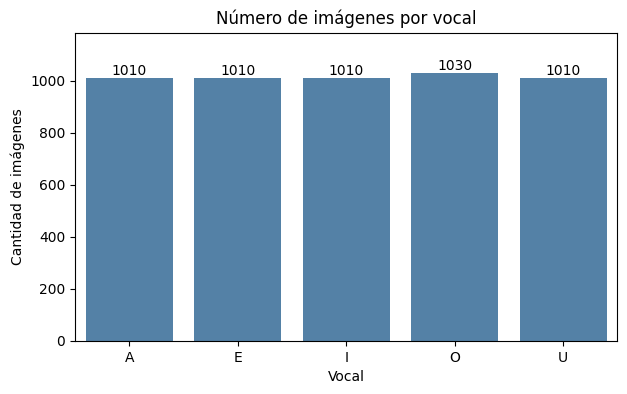

In [6]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=df_conteos, x="Vocal", y="Cantidad", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Número de imágenes por vocal")
plt.xlabel("Vocal")
plt.ylabel("Cantidad de imágenes")
plt.ylim(0, df_conteos["Cantidad"].max() * 1.15)
plt.show()

Las clases están **balanceadas**: la diferencia entre la clase más grande (O, 1030) y las demás (1010) es de solo 20 imágenes, menos del 2 %. Esto evita que un modelo se incline hacia una clase en particular.

### Representación de las imágenes

Se muestra un ejemplo de cada vocal y se revisa cómo se representa una imagen internamente, es decir, la variable predictora X.

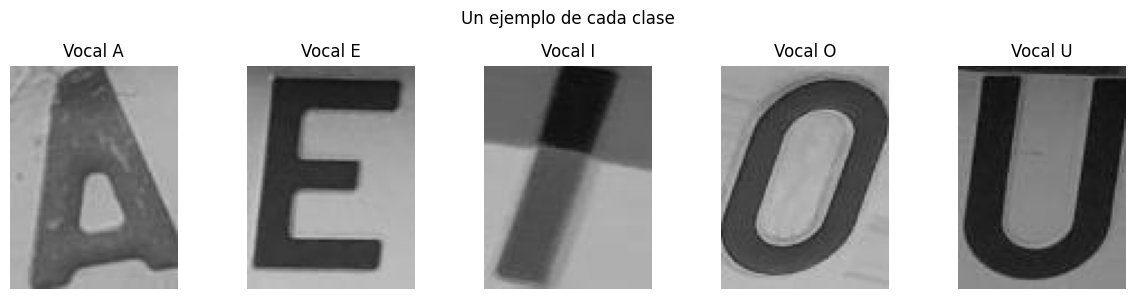

In [7]:
fig, axes = plt.subplots(1, len(carpetas), figsize=(12, 3))
for ax, carpeta in zip(axes, sorted(carpetas, key=lambda c: nombre_vocal[c])):
    primer_archivo = sorted(os.listdir(os.path.join(RUTA, carpeta)))[0]
    img = ski.io.imread(os.path.join(RUTA, carpeta, primer_archivo))
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Vocal {nombre_vocal[carpeta]}")
    ax.axis("off")
plt.suptitle("Un ejemplo de cada clase")
plt.tight_layout()
plt.show()

In [8]:
ruta_ejemplo = os.path.join(RUTA, "A", archivos_A[0])
img = ski.io.imread(ruta_ejemplo)

print("Archivo:", ruta_ejemplo)
print("Tipo de objeto:", type(img))
print("Forma (alto, ancho):", img.shape)
print("Número de dimensiones:", img.ndim)
print("Tipo de dato:", img.dtype)
print("Valor mínimo:", img.min(), "| Valor máximo:", img.max())
print("Número total de píxeles (variables de entrada):", img.size)
print("\nFragmento de la matriz (filas 45 a 49, columnas 30 a 37):")
print(img[45:50, 30:38])

Archivo: Only Vowels\A\aug100_19.jpg
Tipo de objeto: <class 'numpy.ndarray'>
Forma (alto, ancho): (100, 75)
Número de dimensiones: 2
Tipo de dato: uint8
Valor mínimo: 59 | Valor máximo: 194
Número total de píxeles (variables de entrada): 7500

Fragmento de la matriz (filas 45 a 49, columnas 30 a 37):
[[ 83  83  82  81  79  77  76  77]
 [ 82  80  79  77  74  72  71  73]
 [ 82  79  77  75  71  68  68  71]
 [ 79  80  74  70  69  87 114 122]
 [ 81  79  65  76  91 119 149 158]]


Cada imagen se carga como un arreglo de NumPy de forma **(100, 75)**: 100 píxeles de alto por 75 de ancho. Tiene **2 dimensiones**, lo que indica que está en escala de grises (un solo canal). Los valores son enteros de 8 bits (`uint8`) en el rango 0–255, donde 0 es negro y 255 blanco. En total, cada imagen aporta **7500 píxeles**, que son los valores numéricos con los que el modelo trabajará como variable predictora X.

# Inspección y exploración del Dataset

En esta sección se explora el conjunto de datos mediante herramientas gráficas (cuadrículas de imágenes, histogramas, diagramas de caja, gráficas de dispersión y mapas de calor), resúmenes estadísticos y matrices de correlación.

Como los datos son imágenes. Además de inspeccionarlas visualmente, se calculan **características estadísticas de cada imagen** (brillo, contraste, proporción de la letra, nitidez, etc.) para poder resumirlas y analizar su distribución y sus correlaciones.

### Carga de las imágenes y conversión a escala de grises

Se cargan todas las imágenes. Para garantizar que todas tengan un solo canal, se define la función `convertir_a_gris()`: si una imagen viene a color, la convierte a escala de grises con la fórmula del estándar ITU-R BT.601, que combina los canales rojo, verde y azul con pesos de 0,299, 0,587 y 0,114; si ya está en gris, la deja igual. Las imágenes se guardan en el arreglo **X** y sus etiquetas en **y**.

In [9]:
def convertir_a_gris(img):
    if img.ndim == 3:                         # imagen con varios canales (color)
        img = img[:, :, :3].astype(float)     # se descarta la transparencia si existe
        img = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
        img = img.round().astype(np.uint8)    # de vuelta a enteros 0-255
    return img

imagenes, etiquetas = [], []
a_color = 0
for carpeta in carpetas:
    for archivo in sorted(os.listdir(os.path.join(RUTA, carpeta))):
        img = ski.io.imread(os.path.join(RUTA, carpeta, archivo))
        if img.ndim == 3:
            a_color += 1
        imagenes.append(convertir_a_gris(img))
        etiquetas.append(nombre_vocal[carpeta])

X = np.array(imagenes)
y = np.array(etiquetas)
vocales = sorted(np.unique(y))

print("Imágenes que venían a color y se convirtieron:", a_color)
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Imágenes que venían a color y se convirtieron: 0
Forma de X: (5070, 100, 75)
Forma de y: (5070,)


Se cargaron las 5070 imágenes. Ninguna venía a color, lo que confirma que todas ya estaban en escala de grises. **X** tiene forma (5070, 100, 75): 5070 imágenes de 100 × 75 píxeles. **y** contiene las 5070 etiquetas correspondientes.

### Revisión de imágenes repetidas y variantes

Se revisa si hay imágenes exactamente iguales en el conjunto de datos. Para esto se calcula una "huella" de cada imagen a partir de los valores de sus píxeles: dos imágenes con la misma huella son copias idénticas.

In [10]:
huellas = [hashlib.md5(img.tobytes()).hexdigest() for img in X]
repetidas = pd.Series(huellas).duplicated().sum()
print("Imágenes repetidas:", repetidas)

Imágenes repetidas: 0


No hay copias exactas: las 5070 imágenes son distintas entre sí. Sin embargo, que no haya copias exactas no significa que todas las imágenes sean independientes. Los nombres de los archivos tienen el formato `augNNNN_V.jpg`, donde `NNNN` es un número consecutivo y `V` indica el número de variante. A continuación se ordenan los archivos por su número para analizar ese patrón.

In [11]:
archivos = pd.DataFrame(
    [(carpeta, archivo) for carpeta in carpetas
     for archivo in sorted(os.listdir(os.path.join(RUTA, carpeta)))],
    columns=["carpeta", "archivo"],
)
archivos["numero"] = archivos["archivo"].str.split("_").str[0].str.replace("aug", "").astype(int)
archivos["variante"] = archivos["archivo"].str.split("_").str[1].str.replace(".jpg", "").astype(int)
archivos["vocal"] = y

# Cada vez que la variante vuelve a 0 empieza un grupo nuevo
orden = archivos.sort_values(["carpeta", "numero"])
orden["grupo"] = (orden["variante"] == 0).cumsum() - 1
archivos["grupo"] = orden["grupo"]
grupos = archivos["grupo"].to_numpy()

archivos.sort_values(["carpeta", "numero"]).head(12)

,carpeta,archivo,numero,variante,vocal,grupo
1010,0,aug8041_0.jpg,8041,0,O,0
1011,0,aug8042_1.jpg,8042,1,O,0
1012,0,aug8043_2.jpg,8043,2,O,0
1013,0,aug8044_3.jpg,8044,3,O,0
1014,0,aug8045_4.jpg,8045,4,O,0
1015,0,aug8046_5.jpg,8046,5,O,0
1016,0,aug8047_6.jpg,8047,6,O,0
1017,0,aug8048_7.jpg,8048,7,O,0
1018,0,aug8049_8.jpg,8049,8,O,0
1019,0,aug8050_9.jpg,8050,9,O,0


Al ordenar los archivos por su número, la variante aumenta de uno en uno (0, 1, 2, …) y luego vuelve a empezar en 0. Cada secuencia que empieza en la variante 0 se considera un **grupo**. Para comprobar qué representa cada grupo, se muestran las primeras 10 imágenes del primer grupo de cada vocal.

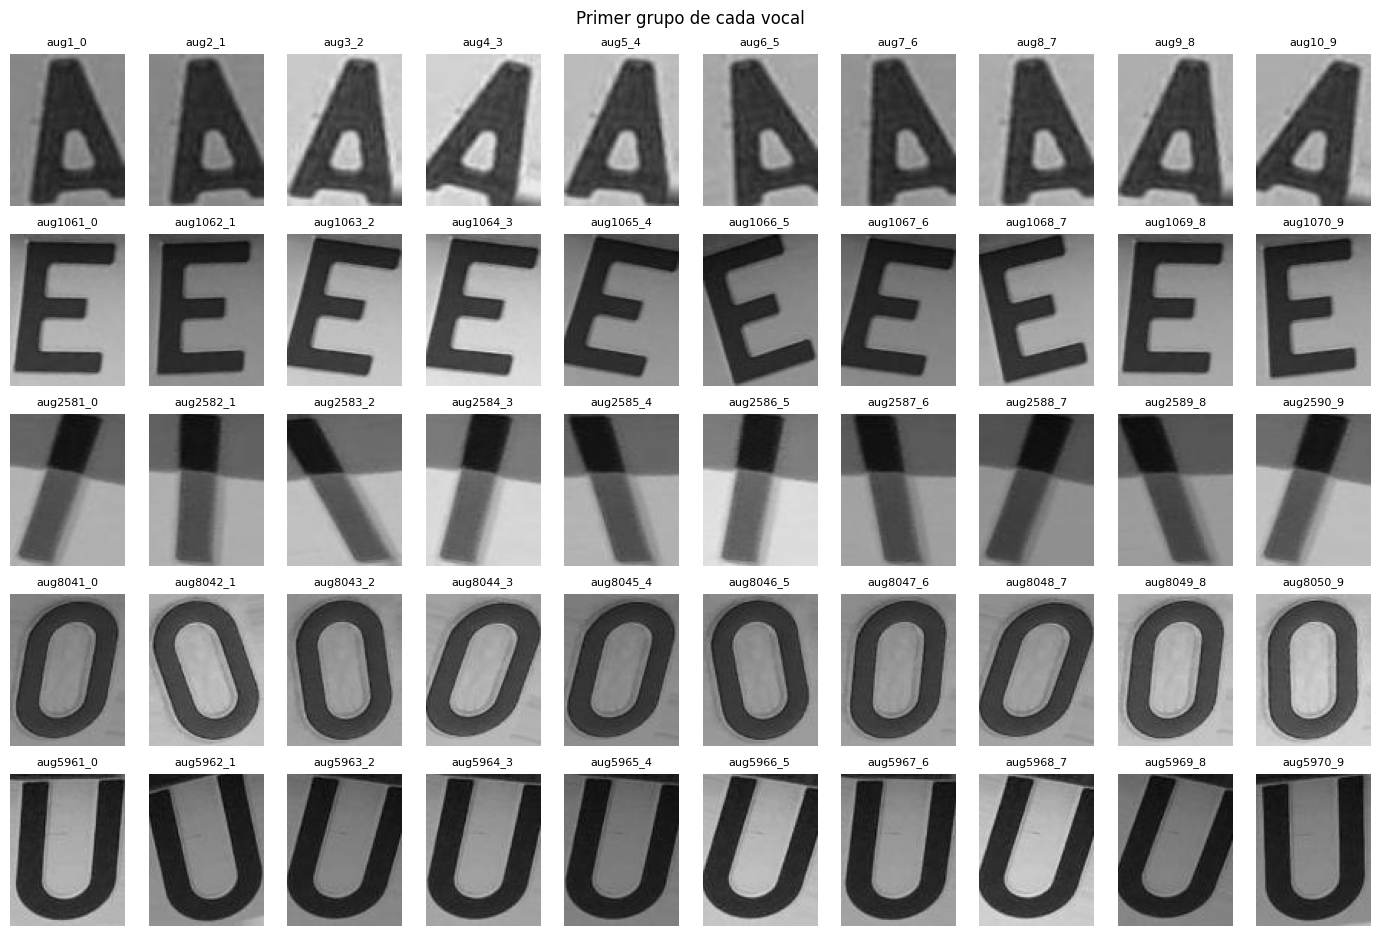

In [31]:
fig, axes = plt.subplots(len(vocales), 10, figsize=(14, 9.5))
for i, vocal in enumerate(vocales):
    primer_grupo = archivos[archivos["vocal"] == vocal]["grupo"].min()
    indices = archivos[archivos["grupo"] == primer_grupo].sort_values("numero").index[:10]
    for j, idx in enumerate(indices):
        axes[i, j].imshow(X[idx], cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(archivos.loc[idx, "archivo"].replace(".jpg", ""), fontsize=8)
        axes[i, j].axis("off")
fig.suptitle("Primer grupo de cada vocal")
plt.tight_layout()
plt.show()

Cada fila muestra la **misma fotografía** con distinta rotación y distinto brillo. Es decir, cada grupo está formado por variantes de una sola foto original, generadas mediante aumento de datos. Las variantes se parecen mucho, pero no son copias exactas, por eso no aparecieron como repetidas en la revisión anterior.

In [32]:
resumen_grupos = archivos.groupby("vocal").agg(
    Imágenes=("archivo", "count"),
    Grupos=("grupo", "nunique"),
)
print(resumen_grupos)
print("\nTotal de grupos:", archivos["grupo"].nunique())
print("Tamaño de los grupos (imágenes por grupo: cantidad de grupos):",
      archivos.groupby("grupo").size().value_counts().sort_index().to_dict())

       Imágenes  Grupos
vocal                  
A          1010      77
E          1010      90
I          1010      74
O          1030     102
U          1010     100

Total de grupos: 443
Tamaño de los grupos (imágenes por grupo: cantidad de grupos): {10: 379, 20: 64}


Las 5070 imágenes provienen de **443 fotografías originales**: 77 de la A, 90 de la E, 74 de la I, 102 de la O y 100 de la U. De esos grupos, 379 tienen 10 variantes y 64 tienen 20.

### Inspección visual de una muestra aleatoria

Se seleccionan 8 imágenes al azar de cada vocal y se muestran en una cuadrícula, una fila por vocal.

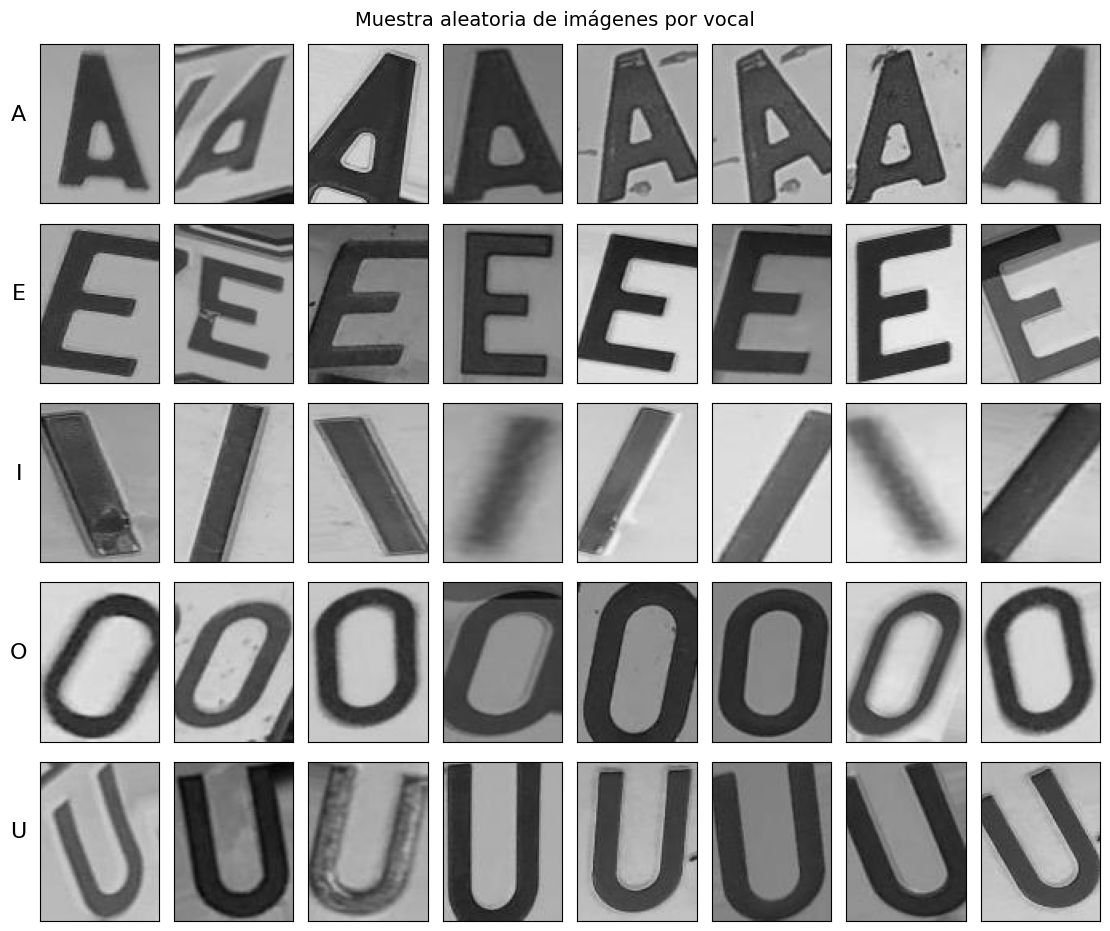

In [12]:
rng = np.random.default_rng(42)  # semilla para que la muestra sea reproducible
N = 8

fig, axes = plt.subplots(len(vocales), N, figsize=(N * 1.4, len(vocales) * 1.9))
for i, vocal in enumerate(vocales):
    indices = rng.choice(np.where(y == vocal)[0], size=N, replace=False)
    for j, idx in enumerate(indices):
        ax = axes[i, j]
        ax.imshow(X[idx], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(vocal, fontsize=16, rotation=0, labelpad=15)
fig.suptitle("Muestra aleatoria de imágenes por vocal", fontsize=14)
plt.tight_layout()
plt.show()

Al observar la muestra se identifican las siguientes variaciones:

*   **Tipo de letra:** aunque el dataset en Kaggle se llama *Handwriting*, las imágenes no parecen escritas a mano, sino fotografías de letras físicas (como las de placas o letreros) con una misma tipografía.
*   **Rotación:** muchas letras aparecen giradas o inclinadas, sobre todo la I y la O.
*   **Escala y recorte:** en algunas imágenes la letra llena el cuadro y queda cortada en los bordes; en otras se ve completa.
*   **Fondo e iluminación:** el fondo va de gris claro a gris oscuro y el contraste entre letra y fondo cambia de una imagen a otra.
*   **Ruido:** algunas imágenes presentan desenfoque, manchas o rayones.
*   La **I** es la vocal más difícil de reconocer a simple vista, porque es solo una barra y con rotación o recorte pierde su forma.

# Imagen promedio de cada vocal

Se calcula el promedio, píxel a píxel, de todas las imágenes de cada vocal. Esto muestra la forma "típica" de cada clase.

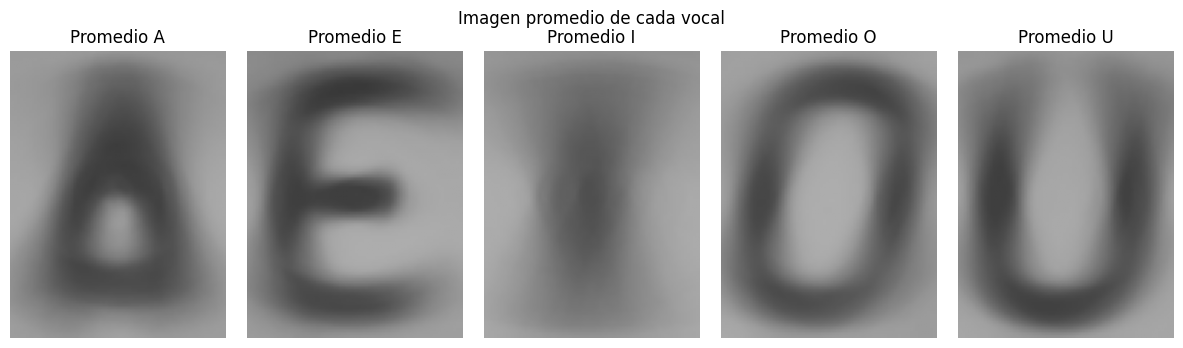

In [13]:
promedios = {}
fig, axes = plt.subplots(1, len(vocales), figsize=(12, 3.5))
for ax, vocal in zip(axes, vocales):
    promedios[vocal] = X[y == vocal].mean(axis=0)
    ax.imshow(promedios[vocal], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Promedio {vocal}")
    ax.axis("off")
fig.suptitle("Imagen promedio de cada vocal")
plt.tight_layout()
plt.show()

A pesar de las rotaciones y variaciones, la imagen promedio de cada vocal conserva una forma reconocible: se distinguen claramente la A, la E, la O y la U. Esto indica que la posición de los píxeles oscuros contiene información útil para clasificar. La **I** es la excepción: su promedio es una mancha difusa, porque la barra aparece en distintas posiciones e inclinaciones. Esto confirma que será la clase más difícil.

También se observa que la O y la U tienen promedios parecidos (ambas tienen trazos verticales a los lados y una curva en la parte inferior), lo que anticipa posibles confusiones entre ellas.

### Distribución de intensidades de los píxeles

Se construye un histograma con los valores de todos los píxeles de cada vocal (de 0 = negro a 255 = blanco).

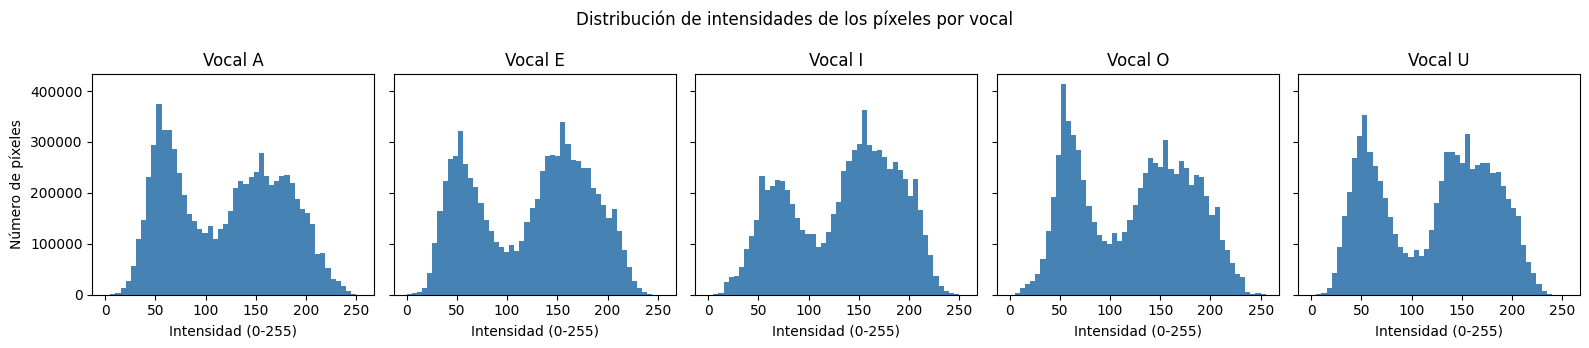

In [14]:
fig, axes = plt.subplots(1, len(vocales), figsize=(16, 3.5), sharey=True)
for ax, vocal in zip(axes, vocales):
    ax.hist(X[y == vocal].ravel(), bins=50, range=(0, 255), color="steelblue")
    ax.set_title(f"Vocal {vocal}")
    ax.set_xlabel("Intensidad (0-255)")
axes[0].set_ylabel("Número de píxeles")
fig.suptitle("Distribución de intensidades de los píxeles por vocal")
plt.tight_layout()
plt.show()

Todos los histogramas tienen dos picos:

*   Un pico en valores bajos (alrededor de 50–60), que corresponde a los píxeles oscuros de la **letra**.
*   Un pico en valores medios-altos (alrededor de 150–170), que corresponde al **fondo**, más claro.

Esta separación indica que la letra y el fondo se pueden distinguir bien por su intensidad. En la **I**, el pico oscuro es más bajo que en las demás vocales porque la letra ocupa una menor parte de la imagen. En la **A** y la **O** ese pico es el más alto, porque su trazo cubre más área.

### Extracción de características estadísticas por imagen

Para resumir cada imagen con pocos valores, se calculan las siguientes características:

| Característica | Descripción |
|---|---|
| `brillo` | Intensidad promedio de la imagen. |
| `contraste` | Desviación estándar de las intensidades . |
| `pixel_mas_oscuro` | Intensidad más oscura de la imagen. |
| `pixel_mas_claro` | Intensidad más clara de la imagen. |
| `area_letra` | Fracción de píxeles que pertenecen a la letra.
| `definicion_bordes` | Mide qué tan definidos son los bordes. Valores bajos indican una imagen borrosa. |

In [15]:
def caracteristicas(img):
    umbral = ski.filters.threshold_otsu(img)
    return {
        "brillo": img.mean(),
        "contraste": img.std(),
        "pixel_mas_oscuro": img.min(),
        "pixel_mas_claro": img.max(),
        "area_letra": (img < umbral).mean(),
        "definicion_bordes": ski.filters.laplace(ski.util.img_as_float(img)).var(),
    }

df = pd.DataFrame([caracteristicas(img) for img in X])
df["vocal"] = y
columnas = ["brillo", "contraste", "pixel_mas_oscuro", "pixel_mas_claro", "area_letra", "definicion_bordes"]

df.sample(10, random_state=42)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes,vocal
2021,153.374933,58.776712,52,217,0.430000,0.005093,A
1840,113.561333,52.638955,25,181,0.432533,0.010758,A
3316,100.652933,41.452041,16,161,0.389333,0.001013,I
1893,87.122800,44.317722,20,150,0.480000,0.003524,A
1988,113.468533,69.492973,9,221,0.515333,0.020419,A
3819,122.549867,38.257939,48,164,0.347600,0.000863,I
2764,144.989067,65.240904,42,217,0.410267,0.003292,E
3630,108.776933,53.283025,17,187,0.488533,0.000882,I
497,111.610933,51.111638,19,184,0.444133,0.004632,O
1032,150.812800,42.814186,63,213,0.448133,0.004536,A


### Resumen estadístico

Se obtiene el resumen estadístico de las características para todo el conjunto de datos y el promedio de cada característica por vocal.

In [16]:
df[columnas].describe().round(3)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes
count,5070.000,5070.000,5070.000,5070.000,5070.000,5070.000
mean,124.780,50.002,27.802,192.217,0.407,0.006
std,23.031,9.926,16.911,28.230,0.082,0.005
min,56.092,22.880,0.000,119.000,0.204,0.000
25%,107.410,42.613,15.000,169.000,0.360,0.002
50%,123.887,49.665,25.000,193.000,0.403,0.004
75%,140.550,56.982,38.000,215.000,0.445,0.008
max,198.193,82.411,123.000,255.000,0.762,0.034


In [17]:
df.groupby("vocal")[columnas].mean().round(3)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes
vocal,,,,,,
A,120.187,50.026,30.128,190.016,0.449,0.005
E,123.462,51.580,23.381,190.402,0.410,0.007
I,134.174,47.362,28.749,194.326,0.354,0.004
O,123.972,49.792,29.321,193.104,0.423,0.006
U,122.119,51.256,27.402,193.221,0.396,0.007


*   **Brillo (`brillo`):** el brillo promedio es 124,8, con valores entre 56,1 y 198,2. Hay imágenes mucho más oscuras que otras, es decir, la iluminación varía bastante.
*   **Contraste (`contraste`):** el contraste promedio es 50,0, con valores entre 22,9 y 82,4. En algunas imágenes la letra se distingue poco del fondo.
*   **Tonos extremos (`pixel_mas_oscuro` y `pixel_mas_claro`):** en promedio, el píxel más oscuro de cada imagen tiene un valor de 27,8 y el más claro de 192,2. Solo 96 de las 5070 imágenes (1,9 %) llegan al negro total (0) y solo 10 (0,2 %) al blanco total (255).
*   **Área de la letra (`area_letra`):** en promedio, la letra ocupa el 40,7 % de la imagen, con valores entre 20,4 % y 76,2 %. Al revisar las imágenes con los valores más altos, se observa que son imágenes de la A donde una parte del fondo también es oscura, y ese fondo se cuenta por error como letra. Por eso esta medida no es exacta cuando el fondo tiene zonas oscuras.
*   **Definición de bordes (`definicion_bordes`):** el valor promedio es 0,0057 y la mediana 0,0043, con valores entre 0,0001 y 0,0344. Que el promedio sea mayor que la mediana indica que solo unas pocas imágenes tienen bordes muy marcados. Al ordenar las 5070 imágenes de menor a mayor definición de bordes, las 8 primeras (las más borrosas) son todas de la vocal I.

Por vocal, la **I** se diferencia de las demás: es la de mayor brillo promedio (134,2), la de menor área de letra (35,4 %) y la de bordes menos marcados (0,0038). Esto tiene sentido porque la I es una sola barra delgada, así que ocupa poco espacio en la imagen. La **A** es la de mayor área de letra (44,9 %). Las demás vocales tienen valores muy parecidos entre sí.

### Histogramas de las características

Se grafica la distribución de cada característica para todo el conjunto de datos.

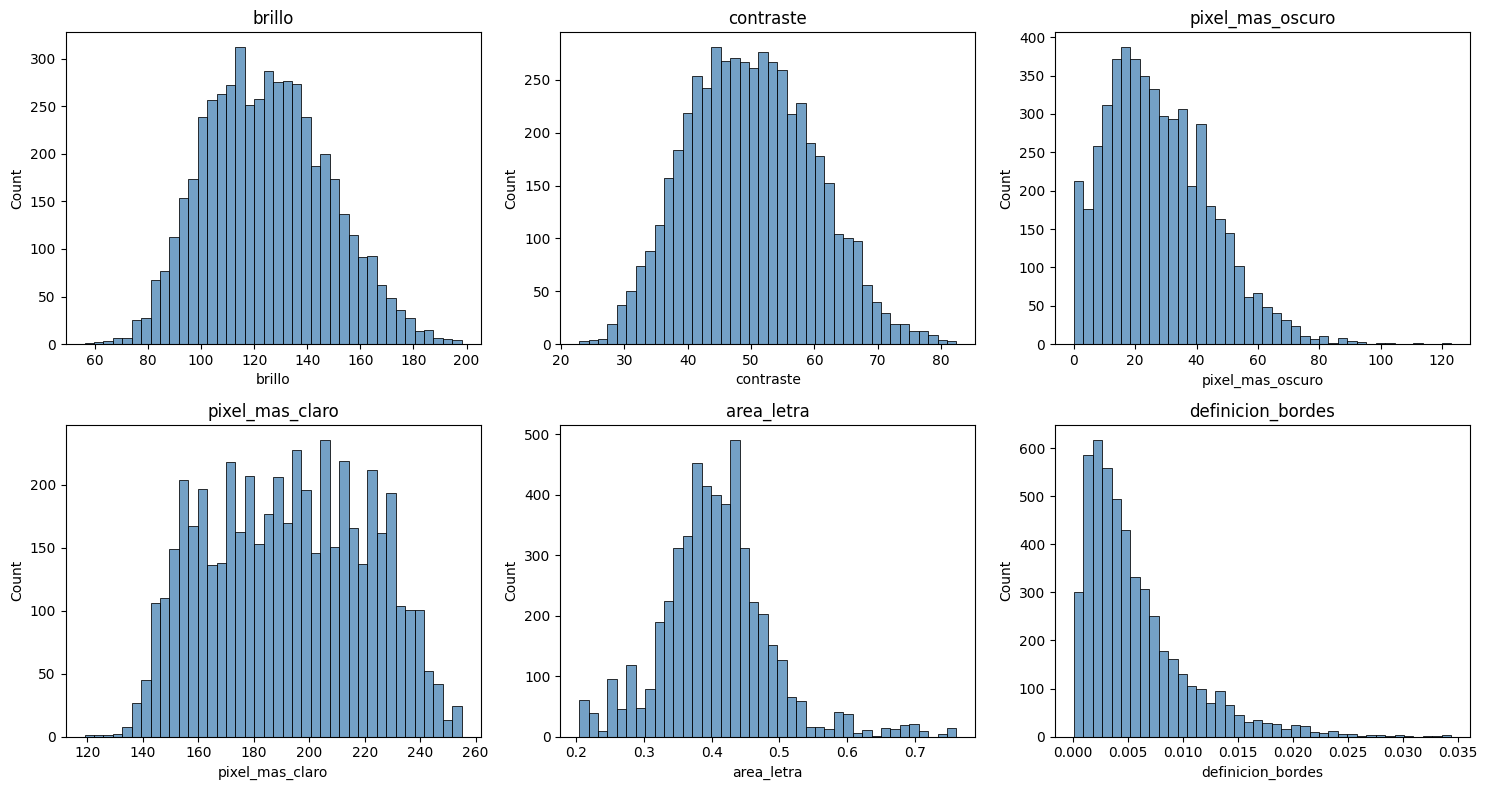

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), columnas):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{col}")
plt.tight_layout()
plt.show()

### Diagramas de caja por vocal

Los diagramas de caja permiten comparar la distribución de cada característica entre las vocales e identificar valores atípicos.

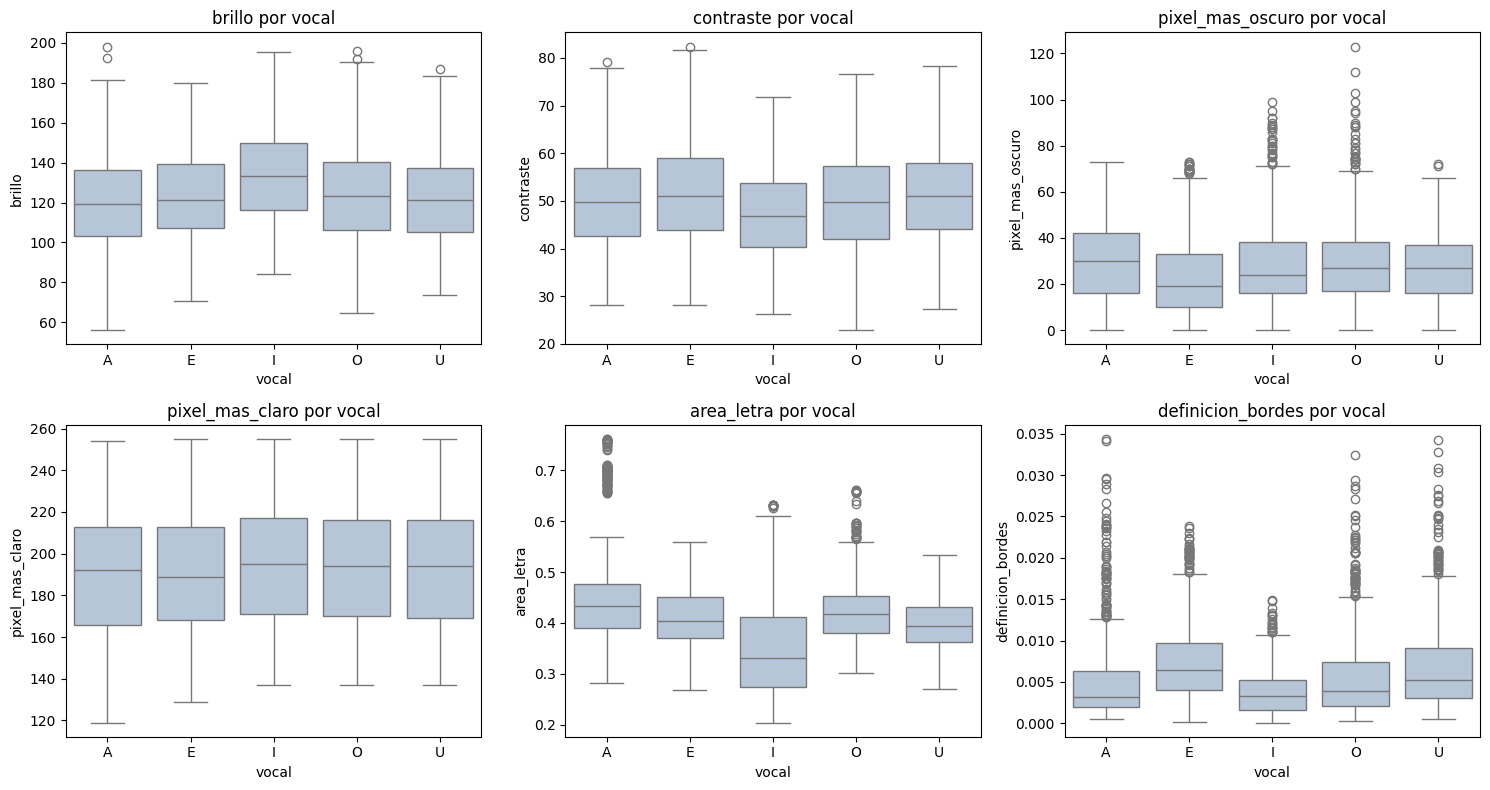

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), columnas):
    sns.boxplot(data=df, x="vocal", y=col, order=vocales, ax=ax, color="lightsteelblue")
    ax.set_title(f"{col} por vocal")
plt.tight_layout()
plt.show()

Para precisar lo que muestran las gráficas, se cuentan los valores atípicos de cada característica por vocal, con la misma regla que usa el diagrama de cajas. También se calcula la asimetría de cada característica: 0 significa que los valores se reparten parejo a ambos lados del centro, y un valor alto, que hay una cola larga hacia un lado.

In [20]:
conteo = {}
for col in columnas:
    conteo[col] = {}
    for vocal, grupo in df.groupby("vocal")[col]:
        q1, q3 = grupo.quantile([0.25, 0.75])
        altura = q3 - q1
        conteo[col][vocal] = ((grupo < q1 - 1.5 * altura) | (grupo > q3 + 1.5 * altura)).sum()

tabla_atipicos = pd.DataFrame(conteo).T
tabla_atipicos["Total"] = tabla_atipicos.sum(axis=1)
tabla_atipicos["Asimetría"] = df[columnas].skew().round(2)
tabla_atipicos.sort_values("Total", ascending=False)

,A,E,I,O,U,Total,Asimetría
definicion_bordes,73,36,21,58,44,232,1.75
area_letra,90,0,10,34,0,134,0.75
pixel_mas_oscuro,0,19,29,30,2,80,0.74
brillo,2,0,0,2,1,5,0.23
contraste,1,1,0,0,0,2,0.19
pixel_mas_claro,0,0,0,0,0,0,0.01


*   La **I** es la vocal que más se diferencia: tiene las imágenes más claras y la letra que ocupa menos espacio. La **A** es la que ocupa más espacio.
*   `definicion_bordes` es la característica con más valores atípicos (232), sobre todo en la A y la O. Esto pasa porque la mayoría de las imágenes tiene valores bajos y solo unas pocas, las de letras grandes y bien enfocadas, tienen valores muy altos.
*   Los valores atípicos no se eliminan, porque son fotos reales con otra iluminación, otro enfoque u otro fondo, no errores.
*   Las cajas de las cinco vocales se superponen bastante, así que estas características por sí solas no permiten diferenciar las vocales. Lo que realmente las distingue es **la forma de la letra**.

### Matriz de correlación entre características

La correlación indica si dos características cambian juntas. Toma valores entre -1 y 1:

*   Cerca de **1**: cuando una aumenta, la otra también aumenta.
*   Cerca de **-1**: cuando una aumenta, la otra disminuye.
*   Cerca de **0**: no hay una relación clara entre ellas.

Se utiliza la correlación de **Spearman**, porque no exige que la relación entre las variables sea una línea recta: solo mide si, cuando una aumenta, la otra tiende a aumentar (o a disminuir). Es la más adecuada aquí porque, como se vio en la sección 2.8, varias características no tienen forma de campana.

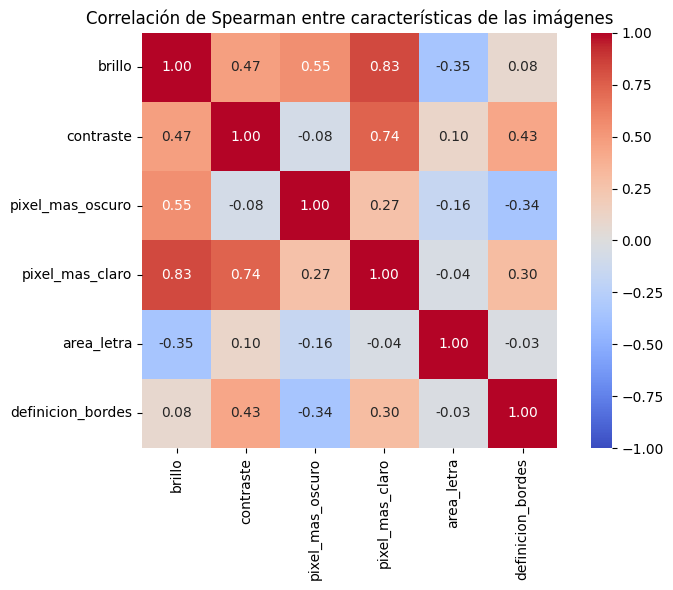

In [21]:
corr = df[columnas].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Spearman entre características de las imágenes")
plt.tight_layout()
plt.show()

*   **`brillo` y `pixel_mas_claro` (0,83):** es la correlación más alta. Las imágenes más claras en general también tienen un fondo más claro, que es donde está el píxel más claro.
*   **`contraste` y `pixel_mas_claro` (0,74):** cuanto más claro es el fondo, más se diferencia de la letra oscura.
*   **`brillo` y `pixel_mas_oscuro` (0,55):** en las imágenes más iluminadas, incluso la letra se ve menos oscura.
*   **`brillo` y `contraste` (0,47)** y **`contraste` y `definicion_bordes` (0,43):** relaciones moderadas. Las imágenes donde la letra se diferencia más del fondo tienden a tener bordes más marcados.
*   **`brillo` y `area_letra` (-0,35):** correlación negativa. Cuanto más espacio ocupa la letra oscura, más oscura es la imagen en general.
*   **`pixel_mas_oscuro` y `definicion_bordes` (-0,34):** en las imágenes donde la letra no llega a verse muy oscura, los bordes tienden a ser menos marcados.
*   `area_letra` tiene una correlación baja con las demás características (excepto con `brillo`), así que aporta información distinta.

#### Revisión del par más correlacionado

Una correlación alta no significa necesariamente que las dos características midan lo mismo y que una de ellas sobre. Para revisarlo, se grafica la relación entre `brillo` y `pixel_mas_claro`.

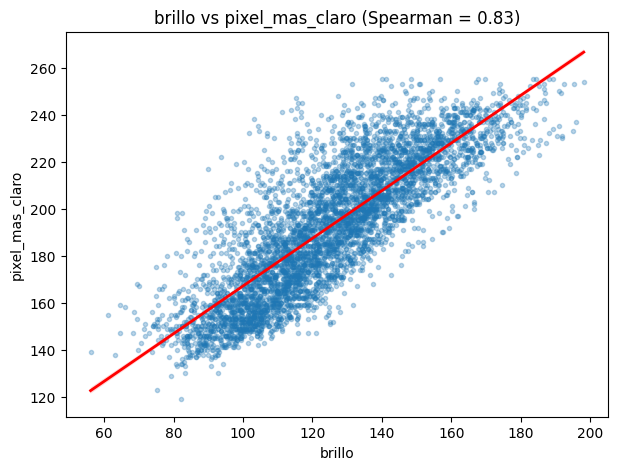

In [22]:
rho = corr.loc["brillo", "pixel_mas_claro"]

plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="brillo", y="pixel_mas_claro", marker=".",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red", "linewidth": 2})
plt.title(f"brillo vs pixel_mas_claro (Spearman = {rho:.2f})")
plt.show()

La gráfica muestra una tendencia clara: cuando aumenta el brillo, también aumenta el píxel más claro. Sin embargo, los puntos están bastante dispersos alrededor de la línea.

Esto ocurre porque miden cosas distintas: `pixel_mas_claro` depende de un solo punto (normalmente en el fondo), mientras que `brillo` depende de toda la imagen, incluido cuánto espacio ocupa la letra oscura. Por lo tanto, aunque están relacionadas, **no son redundantes**, y no se elimina ninguna de las dos en esta etapa.

# Preparación de los datos

En esta sección se describen las estrategias utilizadas para preparar los datos de acuerdo con las necesidades del trabajo. Cada decisión se justifica con lo encontrado durante la inspección del conjunto de datos.


### Conversión de la variable objetivo

La variable objetivo **y** contiene las vocales como texto (A, E, I, O, U), tomadas del nombre de la carpeta de cada imagen. Se convierte a números para que, al igual que las imágenes, quede representada con valores numéricos.

In [23]:
le = LabelEncoder()
y_num = le.fit_transform(y)

pd.DataFrame({
    "Vocal": le.classes_,
    "Número asignado": le.transform(le.classes_),
    "Imágenes": np.bincount(y_num),
})

,Vocal,Número asignado,Imágenes
0,A,0,1010
1,E,1,1010
2,I,2,1010
3,O,3,1030
4,U,4,1010


Cada vocal quedó representada por un número: A = 0, E = 1, I = 2, O = 3 y U = 4.

### Redimensionamiento de las imágenes

Cada imagen tiene 100 × 75 = 7500 píxeles. Se reduce su tamaño para disminuir el número de variables por imagen. Para elegir el tamaño, se comparan varios tamaños que conservan la proporción original (4:3), mostrando una imagen al azar de cada vocal.

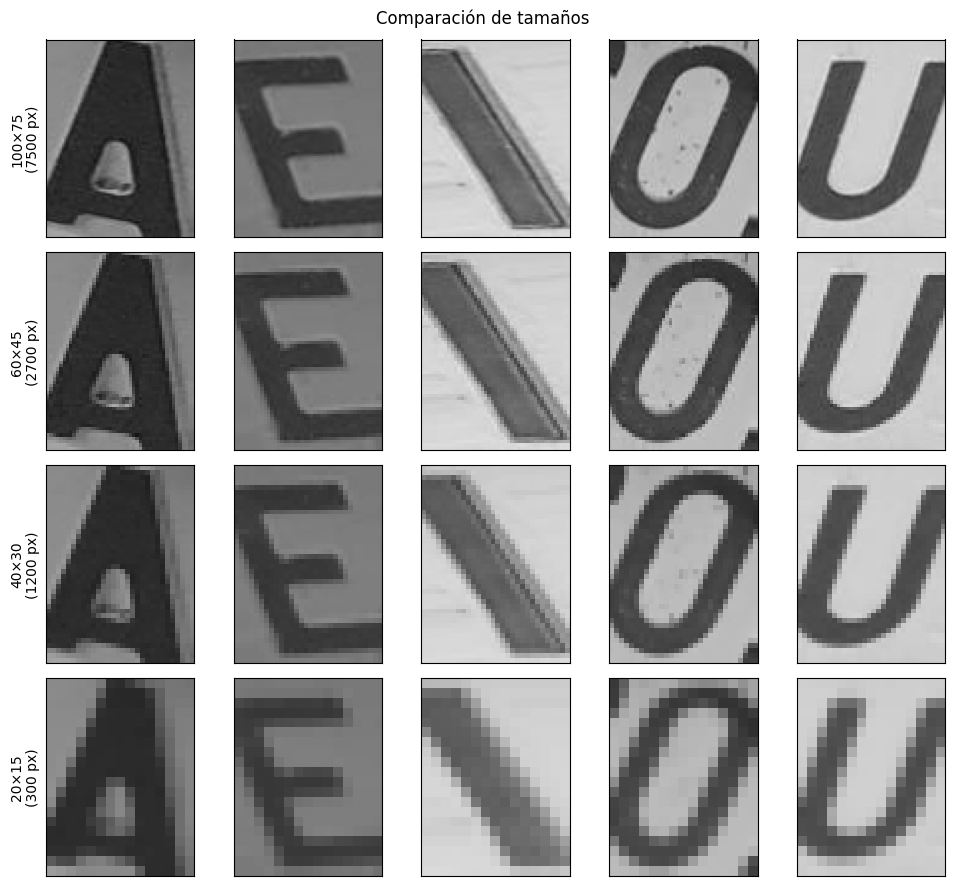

In [24]:
tamanos = [(100, 75), (60, 45), (40, 30), (20, 15)]
rng = np.random.default_rng(0)
ejemplos = [rng.choice(np.where(y == v)[0]) for v in vocales]

fig, axes = plt.subplots(len(tamanos), len(vocales), figsize=(10, 9))
for i, (alto, ancho) in enumerate(tamanos):
    for j, idx in enumerate(ejemplos):
        img = ski.transform.resize(X[idx], (alto, ancho), anti_aliasing=True,
                                   preserve_range=True).round().astype(np.uint8)
        axes[i, j].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
        if j == 0:
            axes[i, j].set_ylabel(f"{alto}×{ancho}\n({alto * ancho} px)")
fig.suptitle("Comparación de tamaños")
plt.tight_layout()
plt.show()

*   En **60 × 45** las imágenes se ven prácticamente iguales a las originales.
*   En **40 × 30** la forma de cada vocal se conserva claramente: se distinguen el hueco de la A, los tres trazos de la E y la curva de la U.
*   En **20 × 15** las imágenes se ven pixeladas y se pierden detalles; por ejemplo, el hueco de la A casi desaparece.

Se elige el tamaño **40 × 30**, que conserva la forma de las letras y reduce cada imagen de 7500 a 1200 píxeles.

In [25]:
ALTO, ANCHO = 40, 30

# anti_aliasing suaviza la imagen antes de reducirla; preserve_range mantiene la escala 0-255
X_red = np.array([
    ski.transform.resize(img, (ALTO, ANCHO), anti_aliasing=True,
                         preserve_range=True).round().astype(np.uint8)
    for img in X
])

print("Forma original:", X.shape)
print("Forma redimensionada:", X_red.shape)
print("Tipo de dato:", X_red.dtype, "| Rango:", X_red.min(), "-", X_red.max())
print("Píxeles por imagen:", ALTO * ANCHO)

Forma original: (5070, 100, 75)
Forma redimensionada: (5070, 40, 30)
Tipo de dato: uint8 | Rango: 1 - 252
Píxeles por imagen: 1200


Las 5070 imágenes quedaron con forma 40 × 30 (40 píxeles de alto por 30 de ancho), es decir, 1200 píxeles por imagen. Los valores siguen siendo enteros (`uint8`) y quedaron entre 1 y 252.

### Vectorización de las imágenes

Los métodos de scikit-learn reciben los datos como una tabla, donde cada fila es un ejemplo y cada columna una variable. Por eso, cada imagen de 40 × 30 se convierte en una fila de 1200 valores, colocando las filas de píxeles de la imagen una después de otra.

In [26]:
X_vec = X_red.reshape(len(X_red), -1)

print("Forma antes:", X_red.shape)
print("Forma después:", X_vec.shape)
print("Primeros 10 píxeles de la primera fila de la imagen:", X_red[0, 0, :10])
print("Primeros 10 valores del vector:                      ", X_vec[0, :10])
print("¿Se puede recuperar la imagen original?:", np.array_equal(X_vec[0].reshape(ALTO, ANCHO), X_red[0]))

Forma antes: (5070, 40, 30)
Forma después: (5070, 1200)
Primeros 10 píxeles de la primera fila de la imagen: [161 161 161 162 162 162 162 162 161 159]
Primeros 10 valores del vector:                       [161 161 161 162 162 162 162 162 161 159]
¿Se puede recuperar la imagen original?: True


El conjunto quedó como una tabla de **5070 filas** (una por imagen) y **1200 columnas** (una por píxel). Los primeros valores del vector coinciden con la primera fila de píxeles de la imagen, y al reorganizar el vector se recupera la imagen original, lo que confirma que la vectorización no pierde información.

### División en conjuntos de entrenamiento y prueba

El trabajo pide evaluar cada modelo sobre un conjunto de prueba. La división se hace en este punto porque el escalamiento y la reducción de dimensionalidad deben ajustarse solo con los datos de entrenamiento: si se ajustaran con todos los datos, la información del conjunto de prueba influiría en la preparación (*data leakage*).

Se reserva el 20 % de las imágenes para prueba. Se usa `stratify` para que cada conjunto conserve la misma proporción de cada vocal.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X_vec, y_num, test_size=0.20, stratify=y_num, random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

tabla_division = pd.DataFrame({
    "Vocal": le.classes_,
    "Entrenamiento": np.bincount(y_train),
    "Prueba": np.bincount(y_test),
})
tabla_division["% en prueba"] = (tabla_division["Prueba"] /
                                 (tabla_division["Entrenamiento"] + tabla_division["Prueba"]) * 100).round(1)
tabla_division

Entrenamiento: (4056, 1200)
Prueba: (1014, 1200)


,Vocal,Entrenamiento,Prueba,% en prueba
0,A,808,202,20.0
1,E,808,202,20.0
2,I,808,202,20.0
3,O,824,206,20.0
4,U,808,202,20.0


Quedaron **4056 imágenes para entrenamiento** y **1014 para prueba**. Cada vocal tiene exactamente el 20 % de sus imágenes en el conjunto de prueba (202 por vocal y 206 para la O), por lo que ambos conjuntos mantienen el balance de clases.

### Escalamiento de los píxeles

Los píxeles toman valores enteros entre 0 y 255. Los métodos que pide el trabajo, como la regresión y las redes neuronales, se entrenan mediante procesos que funcionan mejor cuando las variables tienen valores pequeños y en una misma escala. Por eso, los píxeles se llevan al rango de 0 a 1 dividiéndolos entre 255, que es el valor máximo posible de un píxel. Como se divide entre un valor fijo, la misma operación se aplica igual a entrenamiento y prueba, sin aprender nada de los datos.

In [28]:
X_train_esc = X_train / 255.0
X_test_esc = X_test / 255.0

print(f"Entrenamiento: mínimo {X_train_esc.min():.4f}, máximo {X_train_esc.max():.4f}")
print(f"Prueba:        mínimo {X_test_esc.min():.4f}, máximo {X_test_esc.max():.4f}")

Entrenamiento: mínimo 0.0039, máximo 0.9804
Prueba:        mínimo 0.0078, máximo 0.9882


### Reducción de dimensionalidad con PCA

Cada imagen sigue teniendo 1200 variables. El PCA (Análisis de Componentes Principales) crea nuevas variables, llamadas **componentes principales**, que combinan los píxeles originales y están ordenadas según cuánta de la variación de los datos conservan. Así se puede representar cada imagen con menos valores, perdiendo la menor información posible.

El PCA se ajusta solo con los datos de entrenamiento. Primero se calcula con todos los componentes para ver cuánta variación conservan a medida que se agregan.

In [29]:
pca_completo = PCA()
pca_completo.fit(X_train_esc)
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

for k in [1, 10, 50, 100, 200, 300, 500, 1200]:
    print(f"Con {k:4d} componentes se conserva el {varianza_acumulada[k - 1] * 100:.2f} % de la variación")

Con    1 componentes se conserva el 21.06 % de la variación
Con   10 componentes se conserva el 72.17 % de la variación
Con   50 componentes se conserva el 92.75 % de la variación
Con  100 componentes se conserva el 96.20 % de la variación
Con  200 componentes se conserva el 98.44 % de la variación
Con  300 componentes se conserva el 99.19 % de la variación
Con  500 componentes se conserva el 99.74 % de la variación
Con 1200 componentes se conserva el 100.00 % de la variación


Para elegir el número de componentes se sigue el criterio del ejemplo de PCA de la clase: conservar los componentes necesarios para explicar un alto porcentaje de la variación de los datos, en este caso el **95 %**. Se indica directamente con `n_components=0.95`, y el PCA calcula cuántos componentes necesita para lograrlo. Se ajusta con el conjunto de entrenamiento y luego se aplica al de prueba.

Componentes seleccionados: 77
Variación conservada: 95.04 %
Entrenamiento: (4056, 77)
Prueba: (1014, 77)


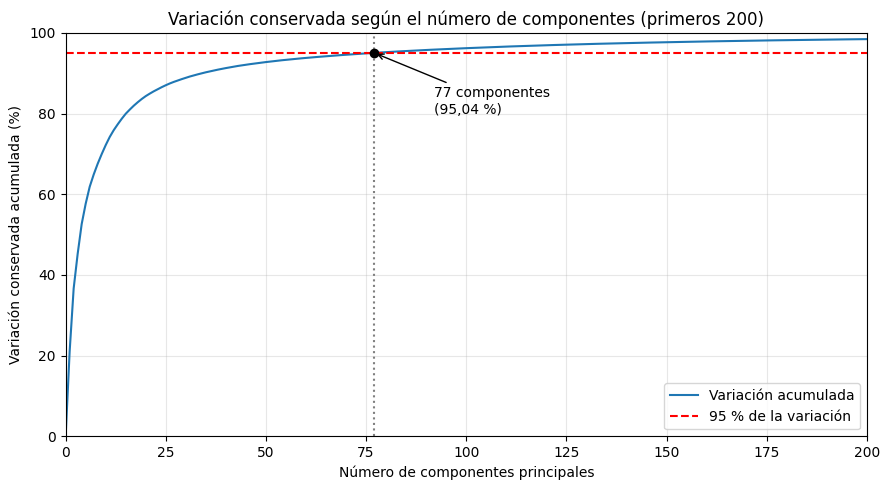

In [30]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_esc)
X_test_pca = pca.transform(X_test_esc)

print("Componentes seleccionados:", pca.n_components_)
print(f"Variación conservada: {pca.explained_variance_ratio_.sum() * 100:.2f} %")
print("Entrenamiento:", X_train_pca.shape)
print("Prueba:", X_test_pca.shape)

k = pca.n_components_
LIMITE = 200
componentes = np.arange(0, LIMITE + 1)                              # desde 0 componentes
curva = np.concatenate(([0], varianza_acumulada[:LIMITE])) * 100   # con 0 componentes: 0 %
porcentaje_k = varianza_acumulada[k - 1] * 100

plt.figure(figsize=(9, 5))
plt.plot(componentes, curva, label="Variación acumulada")
plt.axhline(95, color="red", linestyle="--", label="95 % de la variación")
plt.axvline(k, color="gray", linestyle=":")
plt.plot(k, porcentaje_k, "o", color="black")
plt.annotate(f"{k} componentes\n({porcentaje_k:.2f} %)".replace(".", ","),
             xy=(k, porcentaje_k), xytext=(k + 15, 80),
             arrowprops=dict(arrowstyle="->"))
plt.xlim(0, LIMITE)
plt.ylim(0, 100)
plt.xlabel("Número de componentes principales")
plt.ylabel("Variación conservada acumulada (%)")
plt.title(f"Variación conservada según el número de componentes (primeros {LIMITE})")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Sin componentes no se conserva ninguna variación (0 %); el primer componente, por sí solo, conserva el 21,06 %, por lo que la curva sube bruscamente al inicio. Con 10 componentes se conserva el 72,17 %, y con 50, el 92,75 %. Para conservar el 95 % se necesitan **77 componentes** (95,04 %), como marca el punto negro en la gráfica.

La gráfica muestra solo los primeros 200 componentes porque a partir de ahí la curva es prácticamente plana: con 200 componentes ya se conserva el 98,44 % y con los 1200 el 100 %, según la tabla anterior. En la gráfica se ve que la curva sube rápidamente con los primeros componentes y luego se aplana: después de los 77 componentes, agregar más aporta muy poca variación adicional.

Así, cada imagen pasa de 1200 variables a **77** (93,6 % menos). Que tan pocos componentes conserven casi toda la variación indica que gran parte de la información de los píxeles era repetida. El conjunto de entrenamiento queda con forma (4056, 77) y el de prueba con forma (1014, 77).

### Resumen de las estrategias de preparación

| Estrategia | Descripción |
|---|---|
| Conversión a escala de grises | Se aplicó al cargar las imágenes para garantizar un solo canal. Ninguna imagen venía a color. |
| Conversión de la variable objetivo | Las vocales se convirtieron a números de 0 a 4. |
| Redimensionamiento | Las imágenes pasaron de 100 × 75 a 40 × 30, de 7500 a 1200 píxeles, conservando la forma de las letras. |
| Vectorización | Cada imagen se convirtió en una fila de 1200 valores. |
| División en entrenamiento y prueba | 4056 imágenes para entrenamiento y 1014 para prueba, con el mismo balance de clases. |
| Escalamiento | Los píxeles se llevaron al rango de 0 a 1 con la fórmula Min-Max, usando los límites fijos 0 y 255. |
| Reducción de dimensionalidad | Con PCA, cada imagen pasó de 1200 a 77 variables, conservando el 95 % de la variación. |

Al terminar la preparación, los datos quedan así: **X_train_pca** (4056 × 77) y **y_train** como conjunto de entrenamiento, y **X_test_pca** (1014 × 77) y **y_test** como conjunto de prueba.